# Lab 8: Predictive Analysis and Classification

Compare Logistic Regression, SVM, Decision Tree, and a tuned Random Forest. Features are available before launch; `Outcome`, `LandingPad`, and other post-launch fields are excluded to avoid target leakage.

best model: Decision Tree
best random-forest grid parameters: {'model__max_depth': 3, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
test rows: 23


,model,accuracy,precision,recall,f1,tuned
0,Decision Tree,0.870,0.875,0.933,0.903,False
1,SVM,0.826,0.824,0.933,0.875,False
2,Logistic Regression,0.783,0.812,0.867,0.839,False
3,Tuned Random Forest,0.783,0.812,0.867,0.839,True


confusion matrix (actual rows, predicted columns):


array([[ 6,  2],
       [ 1, 14]])

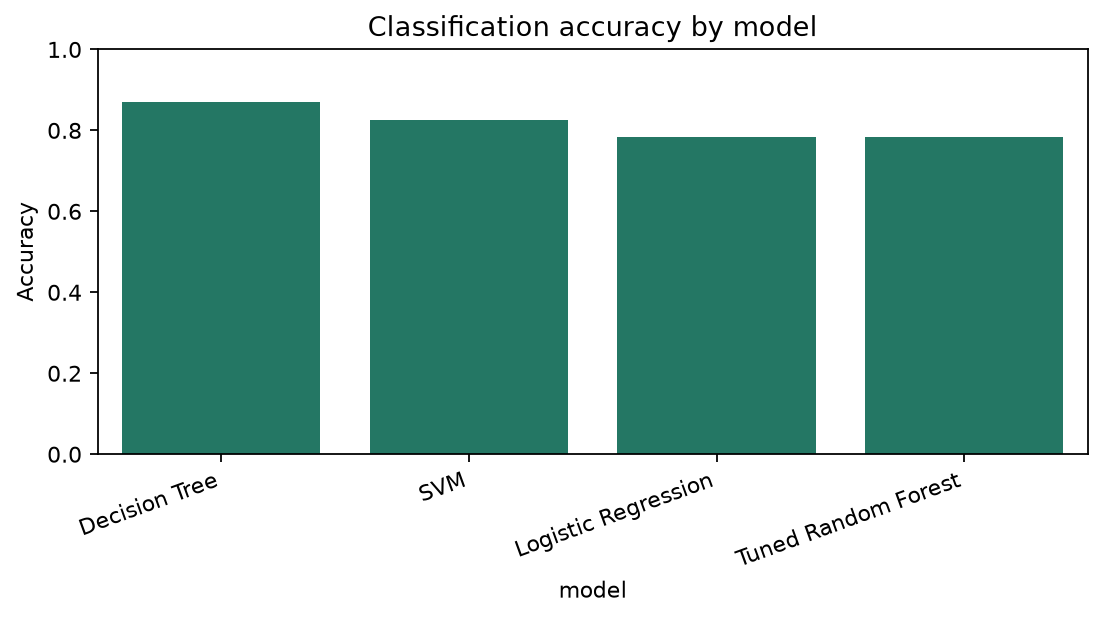

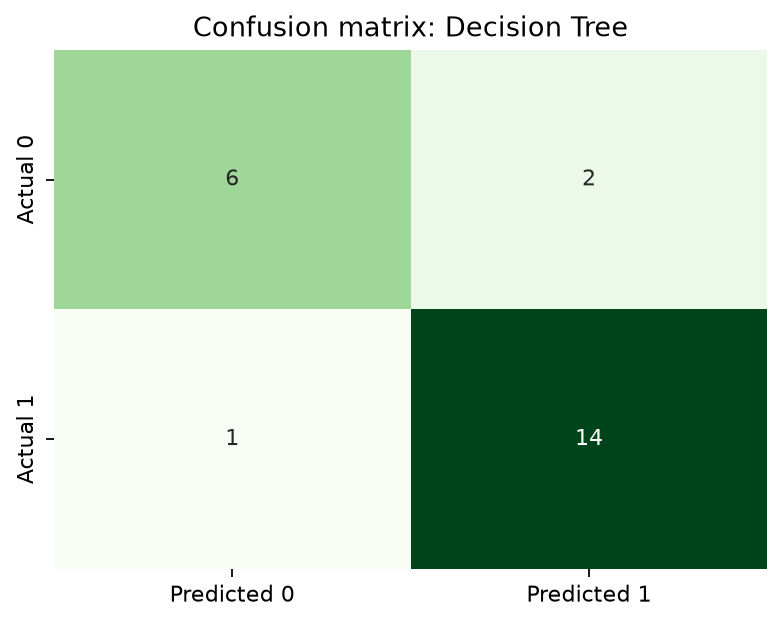

In [1]:
from pathlib import Path
import sys
from IPython.display import Image, display

candidates = [Path.cwd(), *Path.cwd().parents, Path.cwd() / 'spacex-capstone']
PROJECT_DIR = next(path for path in candidates if (path / 'src' / 'spacex_capstone.py').is_file())
sys.path.insert(0, str(PROJECT_DIR / 'src'))
from spacex_capstone import train_classification_models

model_results = train_classification_models()
print('best model:', model_results['best_model'])
print('best random-forest grid parameters:', model_results['best_params'])
print('test rows:', model_results['test_rows'])
display(model_results['metrics'].round(3))
print('confusion matrix (actual rows, predicted columns):')
display(model_results['confusion_matrix'])
display(Image(filename=str(PROJECT_DIR / 'reports' / 'figures' / '10-model-accuracy.png')))
display(Image(filename=str(PROJECT_DIR / 'reports' / 'figures' / '11-best-confusion-matrix.png')))

## Evaluation note

The 90-row labeled dataset uses a stratified 75/25 train-test split with random state 42. Scores are a small-sample baseline and are not evidence of production performance.